In [1]:
import matplotlib.pyplot as plt
import numpy as np
import yt
from yt_derived_fields.cutouts.loader import load_cutout

from tqdm import tqdm

plt.rcParams["figure.dpi"] = 200

We load the dataset with `load_cutout(..., version=2)`. This will create a yt dataset that allows accessing gas and particles.

In [2]:
ds = load_cutout("./data/halo_1438_gas.bin", version=2)

Loading gas cutout: 100%|██████████| 108/108 [00:00<00:00, 298.38it/s]
yt : [INFO     ] 2026-10-15 20:50:52,579 Parameters: current_time              = 2.202629955163893
yt : [INFO     ] 2026-10-15 20:50:52,580 Parameters: domain_dimensions         = [1 1 1]
yt : [INFO     ] 2026-10-15 20:50:52,580 Parameters: domain_left_edge          = [0.49981689 0.49737549 0.49615479]
yt : [INFO     ] 2026-10-15 20:50:52,581 Parameters: domain_right_edge         = [0.50762939 0.50518799 0.50396729]
yt : [INFO     ] 2026-10-15 20:50:52,581 Parameters: cosmological_simulation   = 0


Let's create two particle filters to distinguish young stars from older ones.

In [3]:
young_stars = ds.fields.star.age < ds.quan(100, "Myr")
ds.add_particle_filter(young_stars)

old_stars = ds.fields.star.age > ds.quan(100, "Myr")
ds.add_particle_filter(old_stars)

True

Create two selector for the whole dataset.

__Note__: to build the dataset, we create "fake" cells filled with NaNs. This later messes up with e.g. projection plot, so let's remove them.

In [4]:
ad_all = ds.all_data()
ad = ad_all.exclude_nan(("gas", "density"))
for _ in (ad, ad_all):
    _.set_field_parameter("center", ds.domain_center)

Projection / slices can use yt functionalities for gas quantities...

In [ ]:
p = yt.ProjectionPlot(
    ds,
    "y",
    ("gas", "density"),
    weight_field=("gas", "density"),
    data_source=ad,
    width=(30, "kpc"),
)
p.set_unit(("gas", "density"), "mp/cm**3")
p.set_cmap(("gas", "density"), "plasma")

... or for particles!

yt : [INFO     ] 2026-10-14 15:41:19,634 xlim = 0.499901 0.500431
yt : [INFO     ] 2026-10-14 15:41:19,635 ylim = 0.503239 0.503769
yt : [INFO     ] 2026-10-14 15:41:19,636 xlim = 0.499901 0.500431
yt : [INFO     ] 2026-10-14 15:41:19,637 ylim = 0.503239 0.503769
yt : [INFO     ] 2026-10-14 15:41:19,639 Splatting (("DerivedFieldCombination(terms=[On-Disk Field ('star', 'age'): (units: 'Myr', particle field), unyt_quantity(100, 'Myr')], op=<built-in function lt>)", 'mass')) onto a 800 by 800 mesh using method 'ngp'



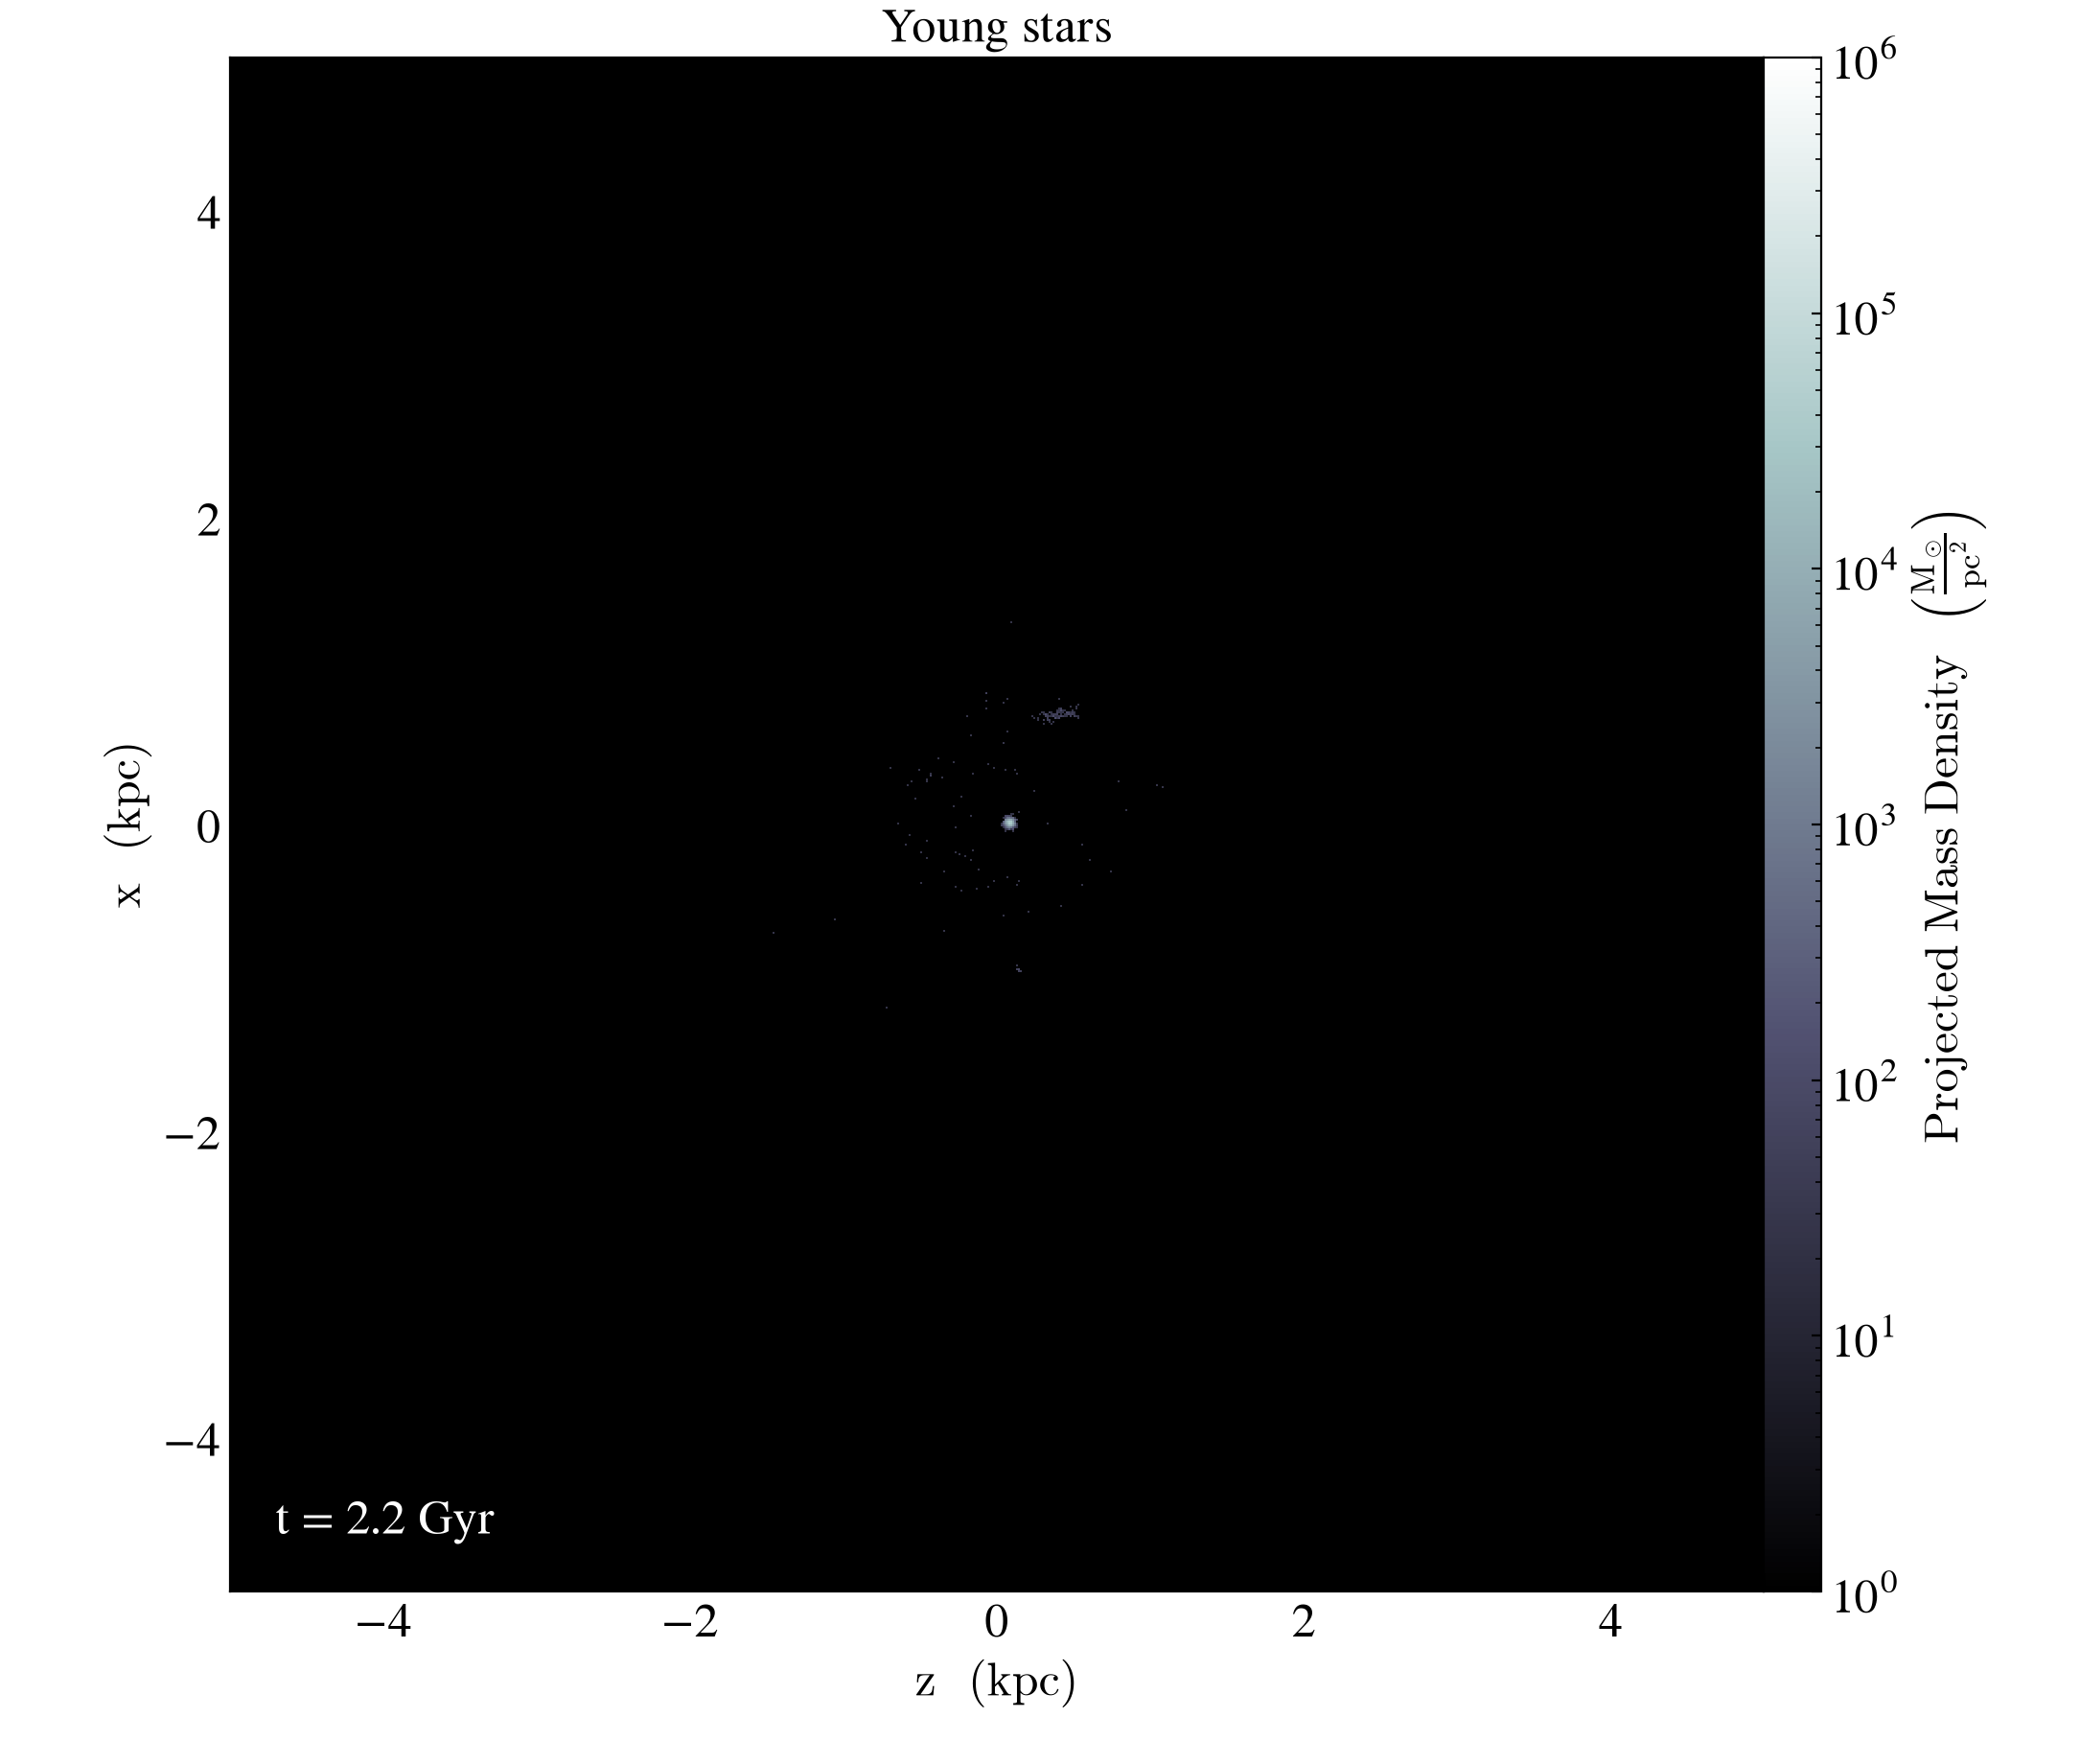

yt : [INFO     ] 2026-10-14 15:41:20,591 xlim = 0.499901 0.500431
yt : [INFO     ] 2026-10-14 15:41:20,592 ylim = 0.503239 0.503769
yt : [INFO     ] 2026-10-14 15:41:20,593 xlim = 0.499901 0.500431
yt : [INFO     ] 2026-10-14 15:41:20,593 ylim = 0.503239 0.503769
yt : [INFO     ] 2026-10-14 15:41:20,594 Splatting (("DerivedFieldCombination(terms=[On-Disk Field ('star', 'age'): (units: 'Myr', particle field), unyt_quantity(100, 'Myr')], op=<built-in function gt>)", 'mass')) onto a 800 by 800 mesh using method 'ngp'



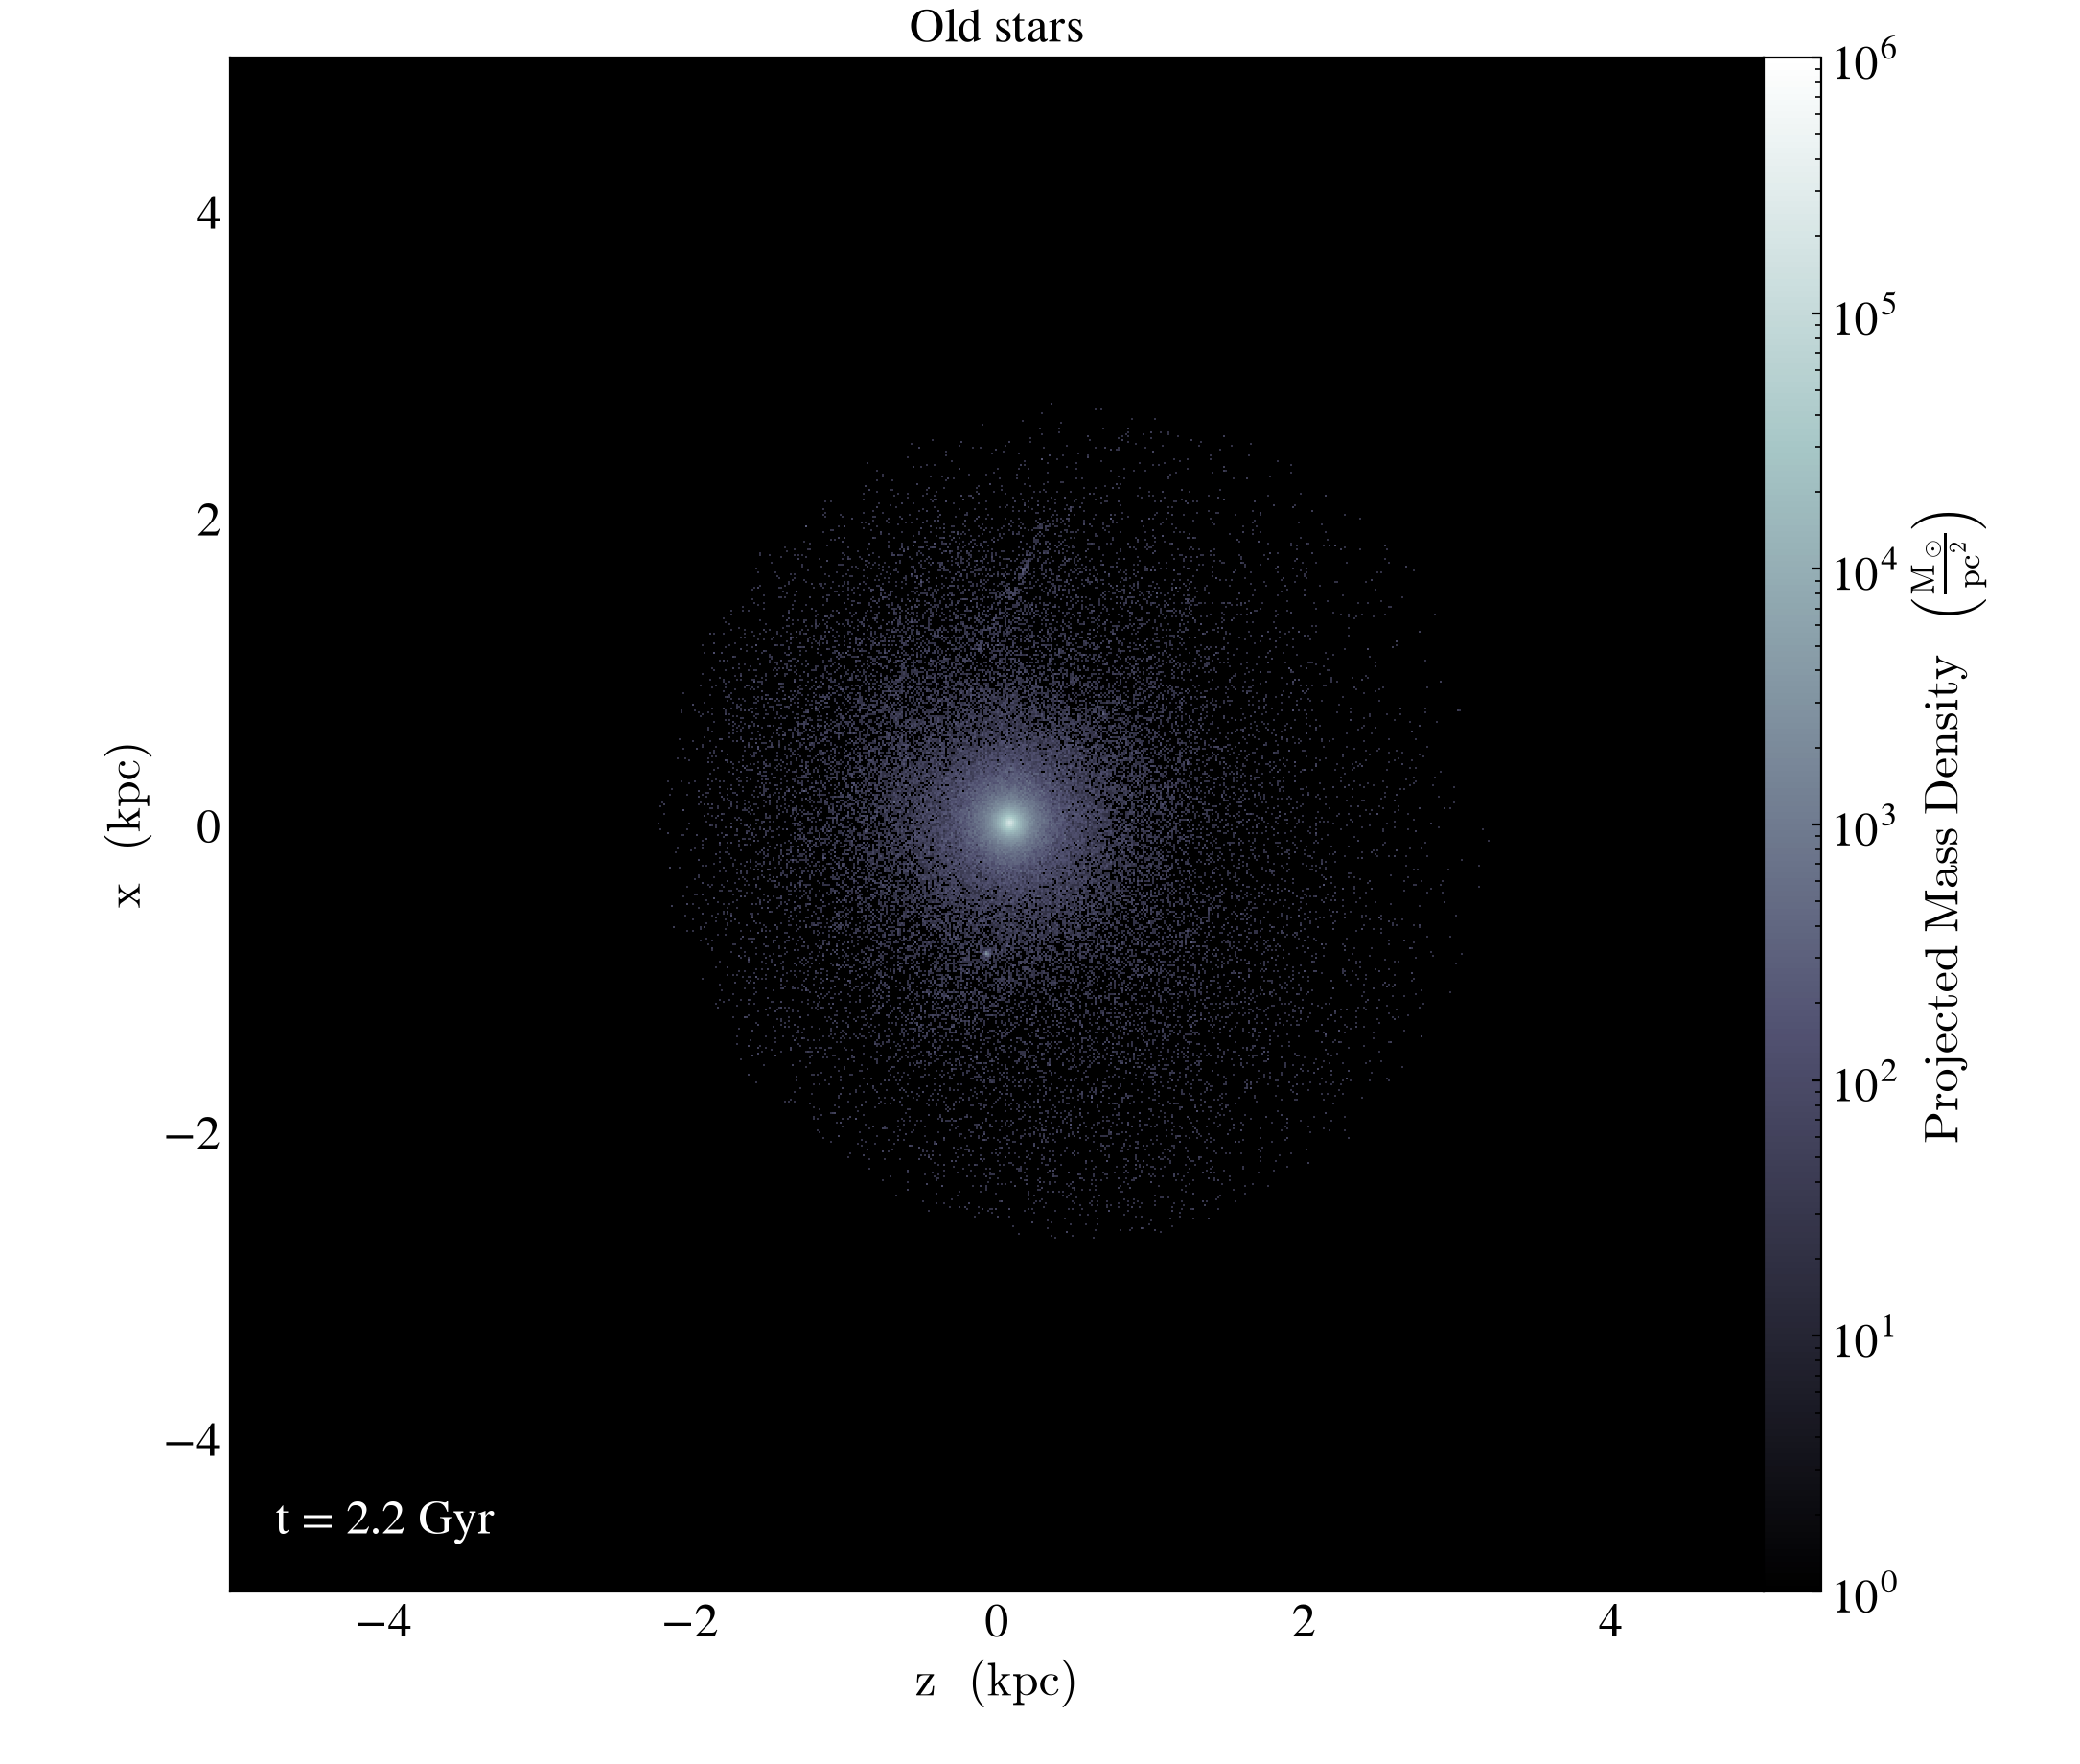

In [ ]:
for ptype, name in zip((young_stars, old_stars), ("Young stars", "Old stars")):
    p = yt.ParticleProjectionPlot(ds, "y", (ptype.name, "mass"), density=True, width=(10, "kpc"))
    p.set_cmap((ptype.name, "mass"), "bone")
    p.set_unit((ptype.name, "mass"), "Msun/pc**2")
    p.set_zlim((ptype.name, "mass"), 1e0, 1e6)
    p.set_background_color("all", "black")
    p.annotate_title(name)
    p.annotate_timestamp()
    p.show()

Alternatively, one can also manually plot, e.g. the particles

[None,
 Text(0.5, 0, '$x$ [$\\mathrm{kpc}$]'),
 Text(0, 0.5, '$y$ [$\\mathrm{kpc}$]')]

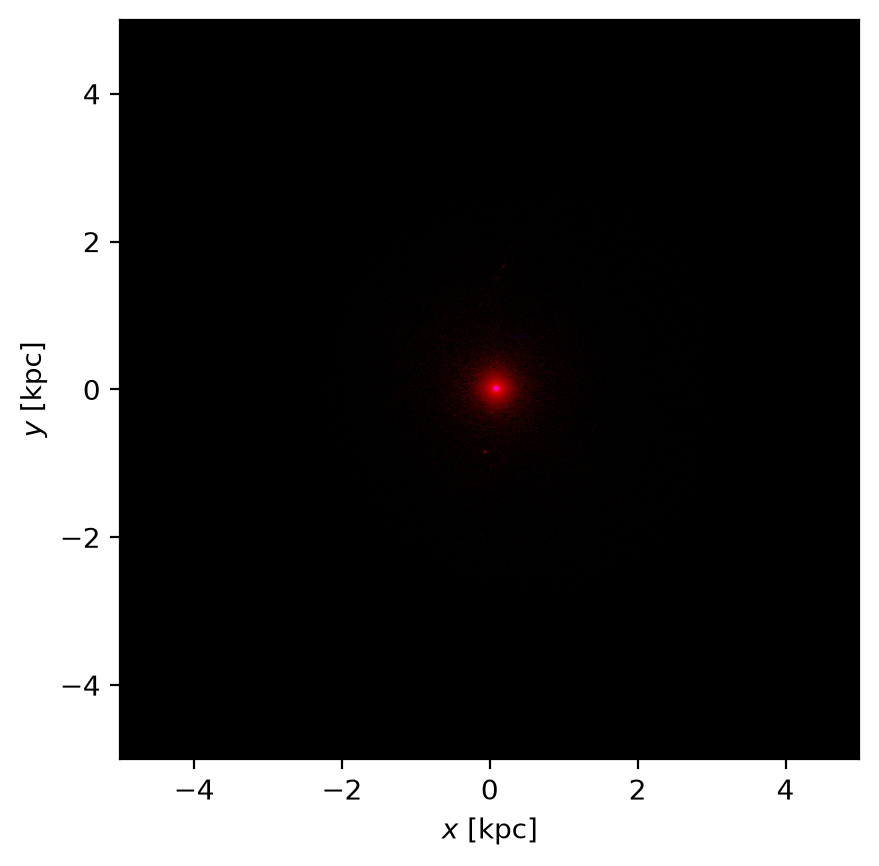

In [ ]:
xfield = "relative_particle_position_x"
yfield = "relative_particle_position_z"

fig, ax = plt.subplots()

N = 2048
w = 5  # kpc

norm = plt.matplotlib.colors.LogNorm(vmin=3e2, vmax=1e6)
data = np.zeros((N, N, 4))
for ptype, kwa, ichannel in zip((young_stars.name, old_stars.name), plt.cycler(cmap=["gray", "gray"]), (2, 0)):
    Sigma, _, _ = np.histogram2d(
        ad_all[ptype, xfield].to("kpc").value,
        ad_all[ptype, yfield].to("kpc").value,
        weights=ad_all[ptype, "mass"].to("Msun"),
        bins=[np.linspace(-w, w, N + 1)] * 2,
    )

    tmp = plt.get_cmap(kwa["cmap"])(norm(Sigma.value))
    data[:, :, ichannel] += tmp[:, :, 0]
    data[:, :, 3] += tmp[:, :, 3]

data = np.clip(data, 0, 1)

ax.imshow(data, extent=(-w, w, -w, w), origin="lower")
ax.set(
    facecolor="black",
    xlabel=r"$x$ [$\mathrm{kpc}$]",
    ylabel=r"$y$ [$\mathrm{kpc}$]",
)

# Phase diagrams of a few ions

100%|██████████| 9/9 [00:19<00:00,  2.18s/it]


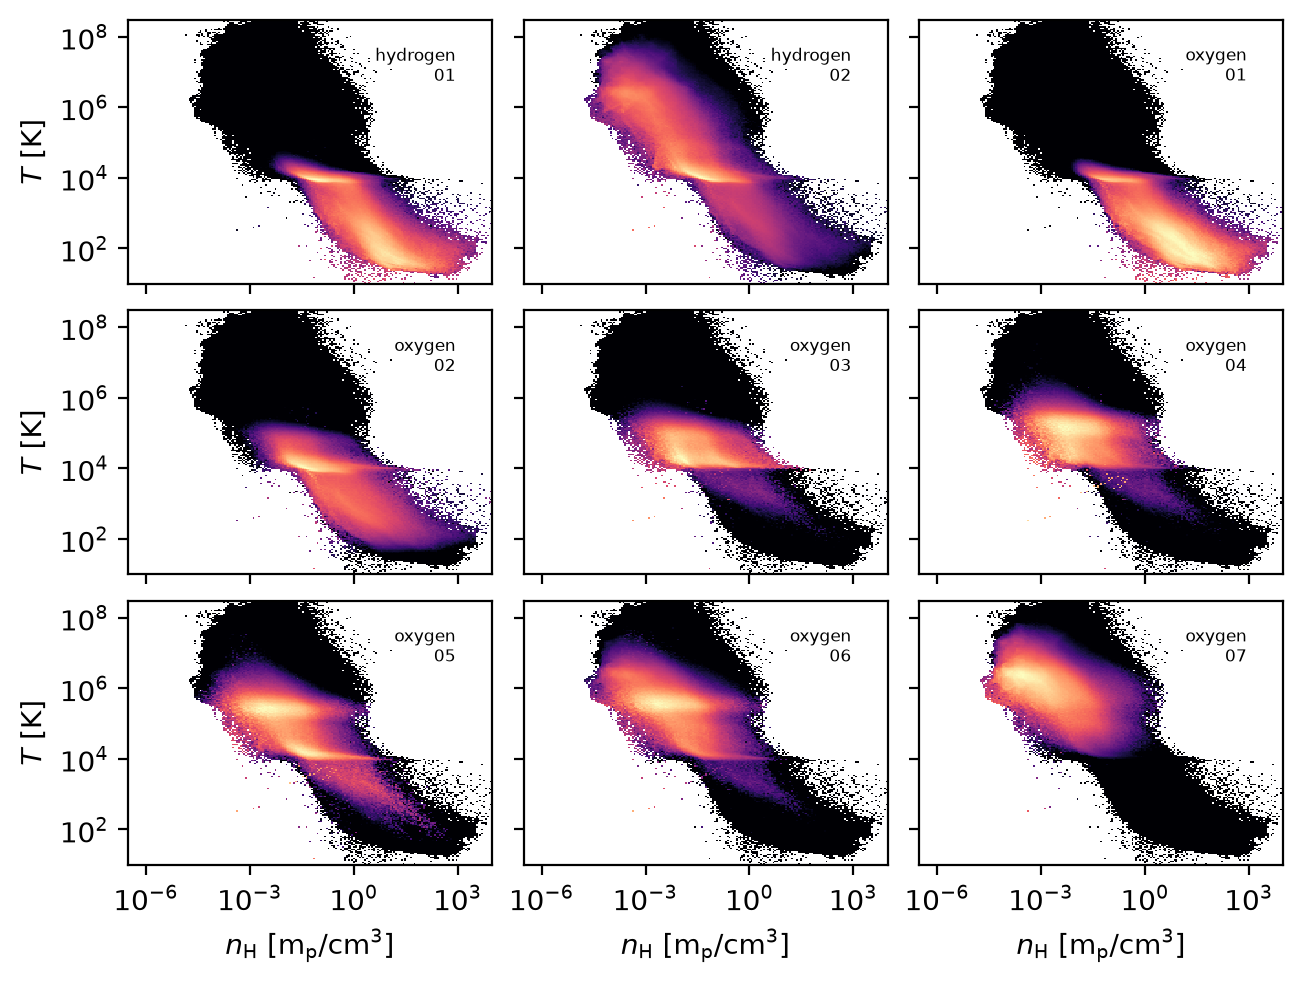

In [ ]:
wfields = [
    "hydrogen_01_number_density",
    "hydrogen_02_number_density",
    *(f"oxygen_{i:02d}_number_density" for i in range(1, 8)),
]
fields = [("gas", "hydrogen_number_density"), ("gas", "temperature")] + wfields

# This triggers the reading form disk (speeds up subsequent calls)
ad.get_data(fields)

rho, T = (
    ad["gas", "hydrogen_number_density"].to("1/cm**3"),
    ad["gas", "temperature"],
)
fig, axes = plt.subplots(ncols=3, nrows=3, constrained_layout=True, sharex=True, sharey=True)

for wfield, ax in zip(
    tqdm(wfields),
    axes.flatten(),
):
    w = ad[wfield] * ad["gas", "cell_volume"]
    *_, IM = ax.hist2d(
        rho.value,
        T.value,
        weights=w,
        bins=(np.geomspace(0.3e-6, 1e4, 200), np.geomspace(10, 3e8, 200)),
        cmap="magma",
        norm=plt.matplotlib.colors.LogNorm(1e-9),
        density=True,
    )
    ax.text(
        0.9,
        0.9,
        "\n".join(wfield.split("_")[:2]),
        transform=ax.transAxes,
        size=6,
        ha="right",
        va="top",
    )

for ax in axes.flatten():
    ax.set(
        xscale="log",
        yscale="log",
    )
    if ax in axes[-1, :]:
        ax.set(
            xlabel=r"$n_\mathrm{H}$ [$\mathrm{m_p/cm^3}$]",
        )
    if ax in axes[:, 0]:
        ax.set(
            ylabel=r"$T$ [$\mathrm{K}$]",
        )

# Evolve the Megatron chemistry and radiation state with RTZ

The cutout stores six integrated radiation energy-flux fields rather than the original photon spectra. They are mapped in order onto the paper's six bands from 5.6 eV upward; the final open-ended band is truncated at 500 eV because RTZ requires finite bounds. We convert each flux to a photon number density using a Planck photon-number-weighted mean energy at RTZ's default `T_blackbody=1e4 K`, and assume the reduced speed of light equals c (fraction 1). The cutout does not retain the within-band spectra or reduced-speed-of-light fraction, so this is an explicit approximation rather than an exact reconstruction.

Helium number density is reconstructed from the cutout gas density using its primordial mass fraction (Y=0.24), because the installed cutout loader does not expose that field. The full initial state and five evolved snapshots are memory-mapped under `rtz_evolution_z2p93/` to avoid keeping all snapshots in RAM; the output requires disk space proportional to six state arrays.

In [ ]:
from pathlib import Path
import json

# Megatron's tracked elements, in the order used by the RTZ state matrix.
elements = [
    "hydrogen",
    "helium",
    "carbon",
    "nitrogen",
    "oxygen",
    "neon",
    "magnesium",
    "silicon",
    "sulfur",
    "iron",
]
atomic_numbers = {
    "hydrogen": 1,
    "helium": 2,
    "carbon": 6,
    "nitrogen": 7,
    "oxygen": 8,
    "neon": 10,
    "magnesium": 12,
    "silicon": 14,
    "sulfur": 16,
    "iron": 26,
}

# Map the six stored integrated fluxes in order to the six RTZ bands from 5.6 eV upward.
photon_bands = [
    (5.6, 11.2),
    (11.2, 13.6),
    (13.6, 15.2),
    (15.2, 24.59),
    (24.59, 54.42),
    (54.42, 500.0),
]
photon_flux_fields = [
    "Habing",
    "Lyman_Werner",
    "HI_Ionising",
    "H2_Ionising",
    "HeI_Ionising",
    "HeII_ionising",
]

available_fields = set(ds.field_list) | set(ds.derived_field_list)
state_fields = [(('gas', 'temperature'), 'K')]
element_density_columns = {}
ion_columns = {element: [] for element in elements}
ions = []

for element in elements:
    density_field = ('gas', f"{element}_number_density")
    if density_field not in available_fields:
        raise RuntimeError(f"Required element density field is missing: {density_field}")
    element_density_columns[element] = len(state_fields)
    state_fields.append((density_field, '1/cm**3'))

for element in elements:
    for iion in range(1, atomic_numbers[element] + 2):
        field = ('gas', f"{element}_{iion:02d}")
        if field not in available_fields:
            break

        ions.append((element, iion))
        ion_columns[element].append(len(state_fields))
        state_fields.append((field, '1'))

photon_columns = []
for field_name in photon_flux_fields:
    field = ('gas', field_name)
    if field not in available_fields:
        raise RuntimeError(f"Required radiation field is missing: {field}")
    photon_columns.append(len(state_fields))
    state_fields.append((field, 'erg/s/cm**2'))

temperature_column = 0
density_offset = 1
ion_offset = density_offset + len(elements)
photon_offset = ion_offset + len(ions)